In [4]:
import json
import pandas as pd

In [6]:
import os
os.chdir('/home/dua/stage_project')

In [7]:
with open(
    "knowledge_base/papers_metadata.json",
    "r",
    encoding="utf-8"
) as f:

    papers = json.load(f)

df = pd.DataFrame(papers)

print(df.shape)

df.head()

(101, 11)


,source,topic,title,abstract,authors,doi,year,pdf_url,category,pdf_path,sha256
0,openalex,bearing failure analysis,Rolling element bearing failure analysis: A ca...,This paper addresses Rolling Contact Fatigue (...,"[Ram Krishna Upadhyay, L.A. Kumaraswamidhas, M...",https://doi.org/10.1016/j.csefa.2012.11.003,2012.0,https://www.sciencedirect.com/science/article/...,bearings,NaN,NaN
1,openalex,bearing failure analysis,Rolling Bearing Analysis,Rolling Bearing Types and Applications Rolling...,"[T. A. Harris, W. J. Crecelius]",https://doi.org/10.1115/1.3261135,1986.0,http://tribology.asmedigitalcollection.asme.or...,bearings,NaN,NaN
2,openalex,bearing failure analysis,Bearing failure analysis of mechanically faste...,,[Heung-Joon Park],https://doi.org/10.1016/s0263-8223(01)00004-6,2001.0,NaN,NaN,NaN,NaN
3,openalex,bearing failure analysis,A study on diesel engine crankshaft bearing fa...,Purpose The edge of diesel engine crankshaft m...,"[Qi Liu, Baiqi Huo, Yunsheng Liu, Junchao Zhu]",https://doi.org/10.1108/ilt-06-2021-0231,2022.0,NaN,NaN,NaN,NaN
4,openalex,bearing failure analysis,Best practices in exploratory factor analysis:...,Exploratory factor analysis (EFA) is a complex...,"[Anna B. Costello, Jason W. Osborne]",https://doi.org/10.7275/jyj1-4868,2020.0,https://scholarworks.umass.edu/pare/vol10/iss1/7,misc,NaN,NaN


In [8]:
df.columns

Index(['source', 'topic', 'title', 'abstract', 'authors', 'doi', 'year',
       'pdf_url', 'category', 'pdf_path', 'sha256'],
      dtype='str')

In [9]:
df["topic"].value_counts()

topic
rotor imbalance                             12
bearing fault diagnosis                     10
motor vibration analysis                    10
electric motor failure analysis              9
motor overheating                            9
bearing failure analysis                     5
bearing wear mechanisms                      5
rotating machinery failure analysis          5
gearbox failure analysis                     5
motor insulation degradation                 5
equipment reliability analysis               5
FMEA bearing failure                         5
FMEA electric motor                          5
failure mode effect analysis maintenance     5
bearing lubrication failure                  4
shaft misalignment                           2
Name: count, dtype: int64

In [10]:
df["source"].value_counts()

source
openalex            73
semantic_scholar    15
arxiv               13
Name: count, dtype: int64

In [11]:
df["year"].value_counts().sort_index()

year
1983.0    1
1986.0    2
1990.0    2
1997.0    5
1999.0    1
2000.0    2
2001.0    1
2002.0    3
2003.0    3
2004.0    2
2005.0    2
2006.0    1
2007.0    1
2010.0    1
2011.0    3
2012.0    2
2013.0    1
2014.0    3
2015.0    3
2016.0    6
2017.0    5
2018.0    4
2019.0    3
2020.0    7
2021.0    3
2022.0    3
2023.0    3
2024.0    6
2025.0    9
Name: count, dtype: int64

### comprendre le vocabulaire

In [12]:
all_text = (
    df["title"].fillna("")
    + " "
    + df["abstract"].fillna("")
)

corpus = " ".join(all_text.tolist())

len(corpus)

92231

In [13]:
from collections import Counter
import re

words = re.findall(
    r"\b[a-zA-Z]{4,}\b",
    corpus.lower()
)

Counter(words).most_common(100)

[('bearing', 121),
 ('motor', 114),
 ('analysis', 109),
 ('this', 101),
 ('with', 92),
 ('failure', 82),
 ('vibration', 81),
 ('that', 78),
 ('fault', 64),
 ('data', 60),
 ('rotor', 58),
 ('based', 55),
 ('paper', 49),
 ('diagnosis', 48),
 ('from', 45),
 ('method', 44),
 ('results', 44),
 ('motors', 43),
 ('systems', 42),
 ('electric', 42),
 ('high', 41),
 ('used', 39),
 ('which', 38),
 ('proposed', 37),
 ('system', 37),
 ('using', 36),
 ('fmea', 36),
 ('monitoring', 35),
 ('reliability', 35),
 ('performance', 33),
 ('power', 33),
 ('methods', 32),
 ('imbalance', 32),
 ('condition', 31),
 ('design', 30),
 ('approach', 29),
 ('learning', 29),
 ('study', 28),
 ('these', 28),
 ('time', 28),
 ('have', 27),
 ('electrical', 27),
 ('control', 27),
 ('current', 27),
 ('wind', 26),
 ('maintenance', 25),
 ('rotating', 24),
 ('model', 24),
 ('faults', 24),
 ('detection', 24),
 ('under', 23),
 ('deep', 23),
 ('machine', 23),
 ('techniques', 22),
 ('research', 22),
 ('mode', 22),
 ('equipment', 22)

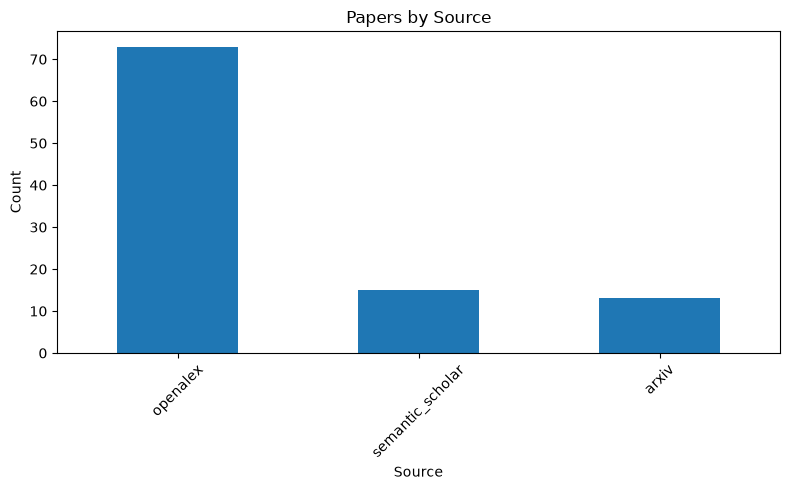

In [17]:
import matplotlib.pyplot as plt

source_counts = df["source"].value_counts()

plt.figure(figsize=(8,5))
source_counts.plot(kind="bar")

plt.title("Papers by Source")
plt.xlabel("Source")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

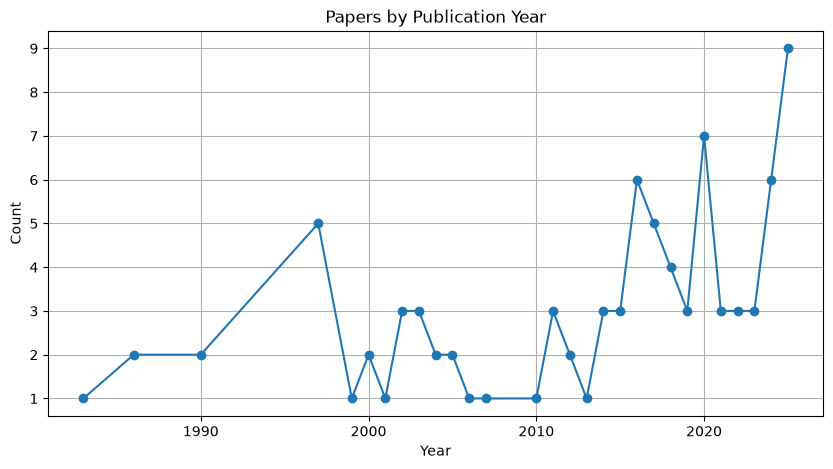

In [18]:
import matplotlib.pyplot as plt

year_counts = (
    df["year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10,5))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker="o"
)

plt.title("Papers by Publication Year")
plt.xlabel("Year")
plt.ylabel("Count")

plt.grid(True)

plt.show()

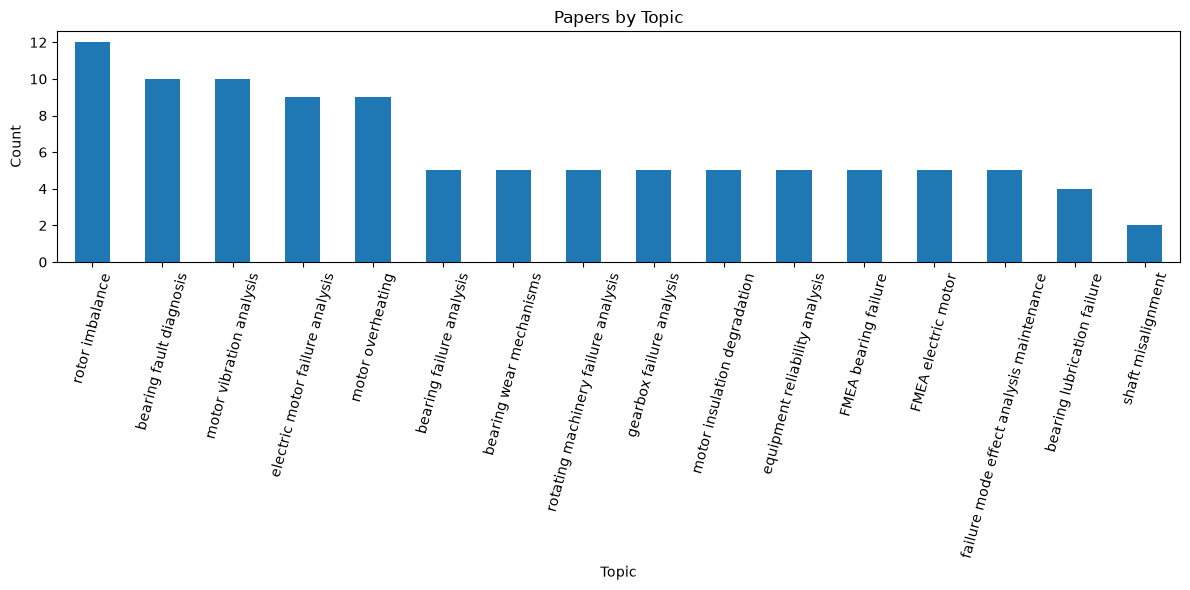

In [19]:
topic_counts = df["topic"].value_counts()

plt.figure(figsize=(12,6))

topic_counts.plot(kind="bar")

plt.title("Papers by Topic")
plt.xlabel("Topic")
plt.ylabel("Count")

plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

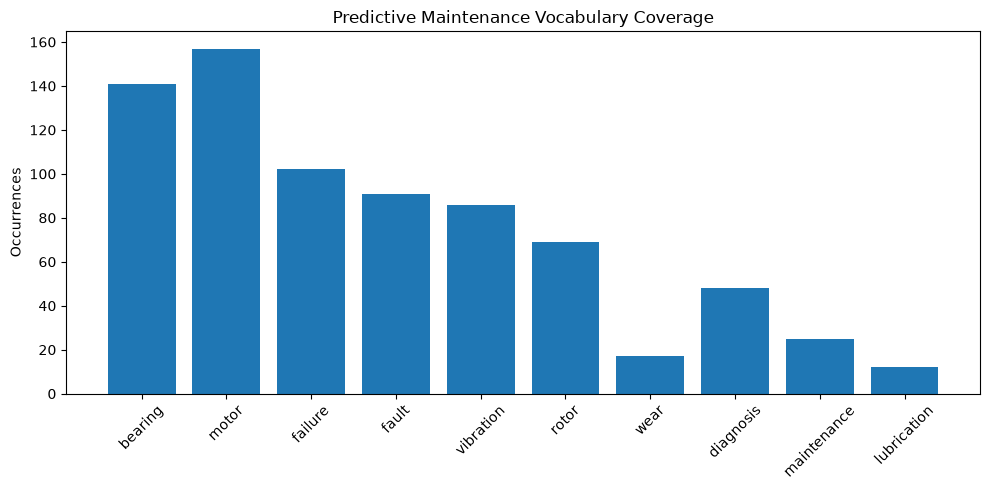

In [ ]:
domain_terms = [
    "bearing",
    "motor",
    "failure",
    "fault",
    "vibration",
    "rotor",
    "wear",
    "diagnosis",
    "maintenance",
    "lubrication"
]

counts = []

for term in domain_terms:

    counts.append(
        corpus.lower().count(term)
    )

plt.figure(figsize=(10,5))

plt.bar(
    domain_terms,
    counts
)

plt.title(
    "Predictive Maintenance Vocabulary Coverage"
)

plt.ylabel("Occurrences")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
!pip install wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.9/554.9 kB 99.1 kB/s eta 0:00:00a 0:00:01


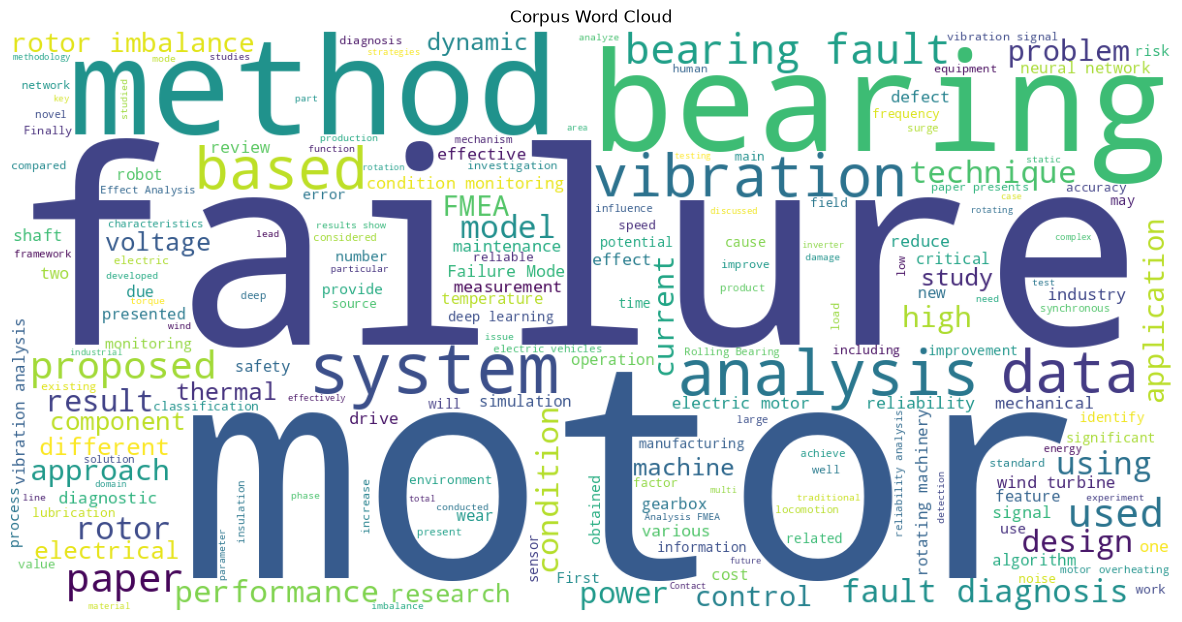

In [22]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white"
).generate(corpus)

plt.figure(figsize=(15,8))

plt.imshow(wordcloud)

plt.axis("off")

plt.title("Corpus Word Cloud")

plt.show()

In [24]:
!pip install networkx

In [25]:
DOMAIN_TERMS = [

    "bearing",
    "motor",
    "failure",
    "fault",
    "vibration",
    "rotor",
    "wear",
    "diagnosis",
    "maintenance",
    "lubrication",
    "gearbox",
    "imbalance",
    "misalignment",
    "temperature",
    "degradation"
]

In [26]:
from collections import Counter
import itertools

co_occurrence = Counter()

texts = (
    df["title"].fillna("")
    + " "
    + df["abstract"].fillna("")
)

for text in texts:

    text = text.lower()

    present_terms = []

    for term in DOMAIN_TERMS:

        if term in text:
            present_terms.append(term)

    for pair in itertools.combinations(
        sorted(set(present_terms)),
        2
    ):

        co_occurrence[pair] += 1

print(
    "Number of relations:",
    len(co_occurrence)
)

co_occurrence.most_common(20)

Number of relations: 84


[(('diagnosis', 'fault'), 20),
 (('bearing', 'failure'), 17),
 (('failure', 'motor'), 17),
 (('fault', 'vibration'), 17),
 (('motor', 'vibration'), 16),
 (('bearing', 'fault'), 15),
 (('bearing', 'vibration'), 14),
 (('diagnosis', 'vibration'), 14),
 (('bearing', 'diagnosis'), 13),
 (('fault', 'motor'), 13),
 (('imbalance', 'rotor'), 12),
 (('failure', 'vibration'), 11),
 (('failure', 'fault'), 11),
 (('rotor', 'vibration'), 9),
 (('diagnosis', 'motor'), 8),
 (('bearing', 'wear'), 7),
 (('bearing', 'motor'), 7),
 (('maintenance', 'vibration'), 7),
 (('fault', 'rotor'), 7),
 (('failure', 'maintenance'), 7)]

In [27]:
import networkx as nx

G = nx.Graph()

for (term1, term2), weight in co_occurrence.items():

    if weight >= 3:

        G.add_edge(
            term1,
            term2,
            weight=weight
        )

print(
    "Nodes:",
    G.number_of_nodes()
)

print(
    "Edges:",
    G.number_of_edges()
)

Nodes: 15
Edges: 47


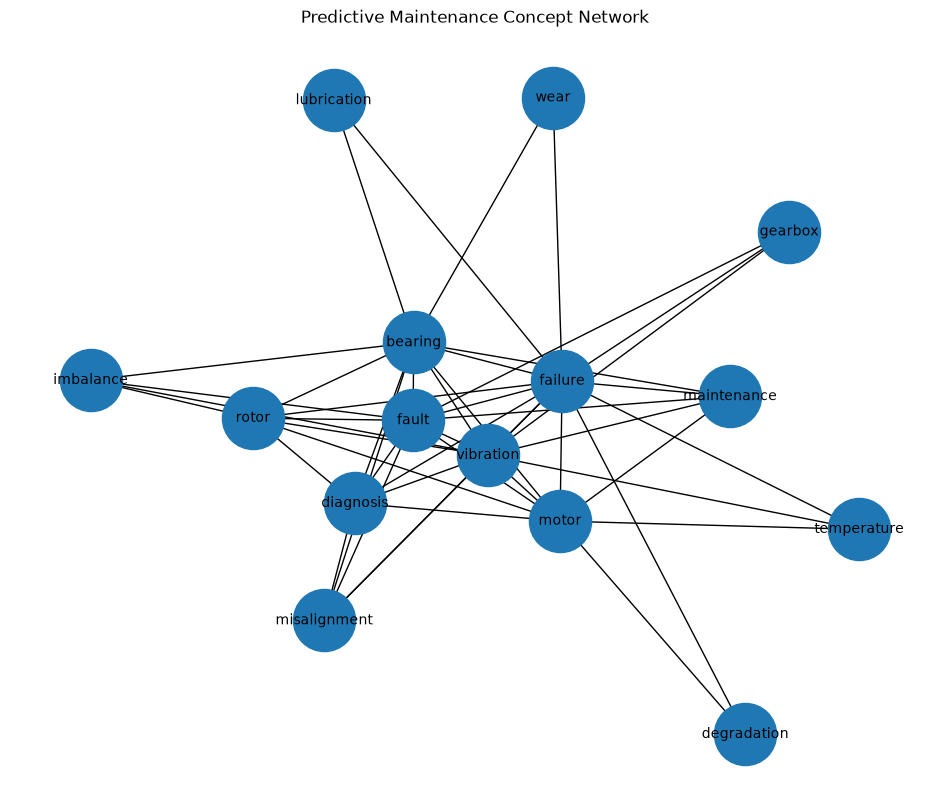

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,10))

pos = nx.spring_layout(
    G,
    seed=42
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2000
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10
)

nx.draw_networkx_edges(
    G,
    pos
)

plt.title(
    "Predictive Maintenance Concept Network"
)

plt.axis("off")

plt.show()

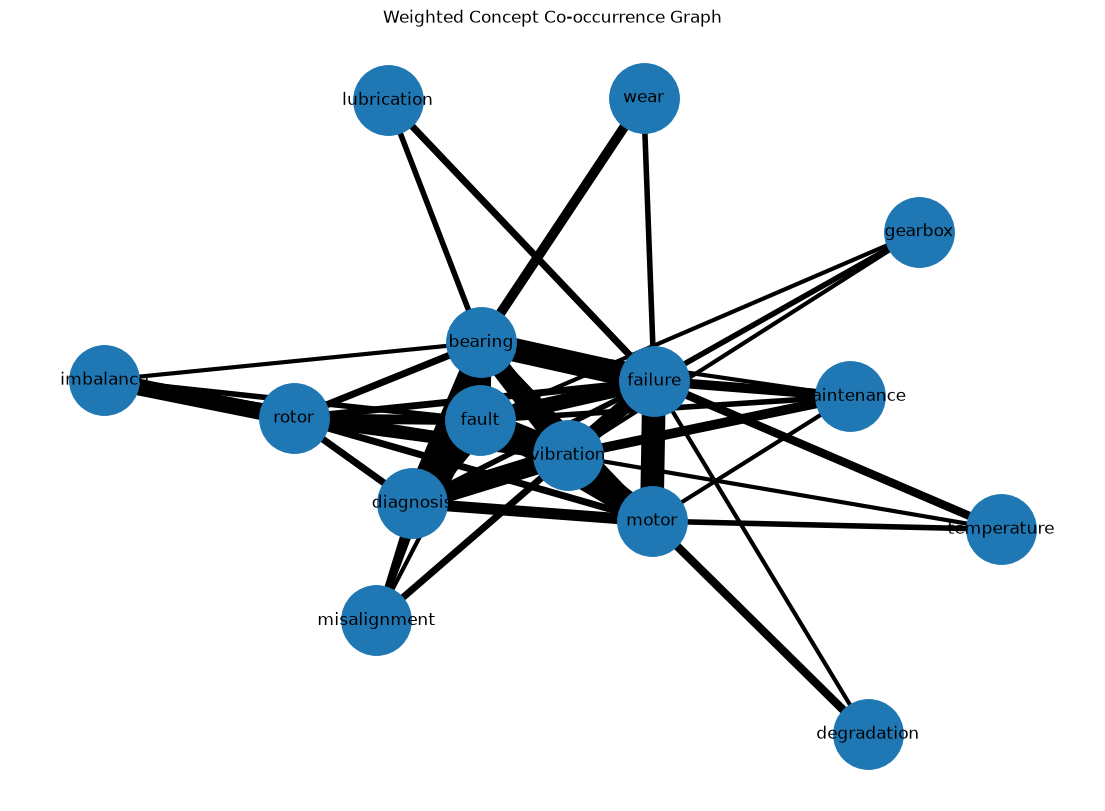

In [29]:
plt.figure(figsize=(14,10))

pos = nx.spring_layout(
    G,
    seed=42
)

weights = [
    G[u][v]["weight"]
    for u, v in G.edges()
]

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2500
)

nx.draw_networkx_labels(
    G,
    pos
)

nx.draw_networkx_edges(
    G,
    pos,
    width=weights
)

plt.title(
    "Weighted Concept Co-occurrence Graph"
)

plt.axis("off")

plt.show()

In [30]:
for pair, count in co_occurrence.most_common(30):

    print(
        f"{pair[0]} <---> {pair[1]} : {count}"
    )

diagnosis <---> fault : 20
bearing <---> failure : 17
failure <---> motor : 17
fault <---> vibration : 17
motor <---> vibration : 16
bearing <---> fault : 15
bearing <---> vibration : 14
diagnosis <---> vibration : 14
bearing <---> diagnosis : 13
fault <---> motor : 13
imbalance <---> rotor : 12
failure <---> vibration : 11
failure <---> fault : 11
rotor <---> vibration : 9
diagnosis <---> motor : 8
bearing <---> wear : 7
bearing <---> motor : 7
maintenance <---> vibration : 7
fault <---> rotor : 7
failure <---> maintenance : 7
failure <---> temperature : 6
degradation <---> motor : 6
bearing <---> rotor : 5
failure <---> lubrication : 5
failure <---> rotor : 5
bearing <---> misalignment : 5
diagnosis <---> rotor : 5
misalignment <---> vibration : 5
motor <---> rotor : 5
bearing <---> lubrication : 4
